In [28]:
import pandas as pd
import numpy as pd
import matplotlib.pyplot as plt
import seaborn as sns

print('all libraries imported successfully')

all libraries imported successfully


In [29]:
import pandas as pd

print(pd.__name__)
print(pd.__version__)
print(pd.read_csv)

pandas
2.2.2
<function read_csv at 0x000002479E525A80>


In [30]:
df=pd.read_csv("../Dataset/Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [31]:
print('Dataset Shape:', df.shape)
print('\nColumn Names:')
print(df.columns.tolist())
print('\nDataset Information:')
df.info()

Dataset Shape: (10000, 14)

Column Names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 1

In [32]:
print('Missing Values:')
print(df.isnull().sum())

Missing Values:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [33]:
# duplicate values check

print('Duplicate Rows:', df.duplicated().sum())

Duplicate Rows: 0


In [34]:
# statistical summary

df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [35]:
# Categorical columns analysis

print('Geography:')
print(df['Geography'].value_counts())

print('\nGender:')
print(df['Gender'].value_counts())

print('\nNumber of Customes by Geography and Gender:')
print(df.groupby(['Geography', 'Gender']).size())

Geography:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender:
Gender
Male      5457
Female    4543
Name: count, dtype: int64

Number of Customes by Geography and Gender:
Geography  Gender
France     Female    2261
           Male      2753
Germany    Female    1193
           Male      1316
Spain      Female    1089
           Male      1388
dtype: int64


In [36]:
# customer churan analysis- checking how many customers left the bank and how many stayed

print('Churan Count:')
print(df['Exited'].value_counts())

print('\nChuran Percentage:')
print(df['Exited'].value_counts(normalize=True) * 100)

Churan Count:
Exited
0    7963
1    2037
Name: count, dtype: int64

Churan Percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [37]:
# overall customer churn rate
# calculating the percentage of customers who left the bank

total_customers = len(df)
churned_customers = df['Exited'].sum()

churn_rate = (churned_customers / total_customers) * 100

print('Total Customers:', total_customers)
print('Churned_Customers:', churned_customers)
print('Customer Churn Rate:', round(churn_rate, 2),'%')

Total Customers: 10000
Churned_Customers: 2037
Customer Churn Rate: 20.37 %


In [38]:
# customer churn analysis by gender
# comparing churned customer based on gender

gender_churn = df.groupby('Gender')['Exited'].sum()

gender_total = df.groupby('Gender')['Exited'].count()

gender_churn_rate = (gender_churn / gender_total) * 100

print('Gender-wise Churn Rate:')
print(gender_churn.round(2))

Gender-wise Churn Rate:
Gender
Female    1139
Male       898
Name: Exited, dtype: int64


In [39]:
# customer churn analysis by geography
# comparing churn rates across different countries

geo_churn = df.groupby('Geography')['Exited'].sum()
geo_total = df.groupby('Geography')['Exited'].count()

geo_churn_rate = (geo_churn / geo_total) * 100

print('Geography-wise Churn Rate:')
print(geo_churn_rate.round(2))

Geography-wise Churn Rate:
Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64


In [40]:
# costomer churn analysis by age group
# division custmers into age groups and comparing churn rates

df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[0,25,35,45,55,100],
    labels=['0-25', '26-35','36-45', '46-55',
'55+']
)

age_churn = df.groupby('Age_Group', observed=True)['Exited'].sum()

age_total = df.groupby('Age_Group', observed=True)['Exited'].count()

age_churn_rate = (age_churn / age_total) * 100

print('Age Group-wise Churn Rate:')
print(age_churn_rate.round(2))

Age Group-wise Churn Rate:
Age_Group
0-25      7.53
26-35     8.50
36-45    19.62
46-55    50.57
55+      36.75
Name: Exited, dtype: float64


In [41]:
# customer churn analysis by credit score
# division customer into credit score categories

df['Credit_Category'] = pd.cut(
    df['CreditScore'],
    bins=[0,580,670,740,800,900],
    labels=['Poor','Fair','Good','Very Good','Excellent']
)

credit_churn = df.groupby('Credit_Category')['Exited'].sum()
credit_total = df.groupby('Credit_Category')['Exited'].count()

credit_churn_rate = (credit_churn / credit_total)*100

print('Credit Score-wise Churn Rate:')
print(credit_churn_rate.round(2))

Credit Score-wise Churn Rate:
Credit_Category
Poor         22.15
Fair         20.39
Good         18.82
Very Good    20.25
Excellent    19.69
Name: Exited, dtype: float64


C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\2296535382.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  credit_churn = df.groupby('Credit_Category')['Exited'].sum()
C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\2296535382.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  credit_total = df.groupby('Credit_Category')['Exited'].count()


In [42]:
# Customer churn analysis by account balance
# comparing churn rates based on cutomer balance

df['Balance_Category'] = pd.cut(
    df['Balance'],
    bins=[-1,0,50000,100000,150000,250000],
    labels=['Zero','Low','Medium','High','Very High',]
)

balance_churn = df.groupby('Balance_Category')['Exited'].sum()
balance_total = df.groupby('Balance_Category')['Exited'].count()

balance_churn_rate = (balance_churn /
balance_total) * 100

print('Balance-wise Churn Rate:')
print(balance_churn_rate.round(2))

Balance-wise Churn Rate:
Balance_Category
Zero         13.82
Low          34.67
Medium       19.88
High         25.77
Very High    23.04
Name: Exited, dtype: float64


C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\2214666742.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  balance_churn = df.groupby('Balance_Category')['Exited'].sum()
C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\2214666742.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  balance_total = df.groupby('Balance_Category')['Exited'].count()


In [43]:
# customer churn analysis by tenure
# comapring churn rates based on how long customers stayed with the bank

tenure_churn = df.groupby('Tenure')['Exited'].sum()
tenure_total = df.groupby('Tenure')['Exited'].count()

tenure_churn_rate= (tenure_churn / tenure_total)*100

print('Tenure-wise Churn Rate:')
print(tenure_churn_rate.round(2))

Tenure-wise Churn Rate:
Tenure
0     23.00
1     22.42
2     19.18
3     21.11
4     20.53
5     20.65
6     20.27
7     17.22
8     19.22
9     21.65
10    20.61
Name: Exited, dtype: float64


In [44]:
# customer churn analysis by active memebrship
# comparing churn rates of active and inactive bank members

active_churn = df.groupby('IsActiveMember')['Exited'].sum()
active_total = df.groupby('IsActiveMember')['Exited'].count()

active_churn_rate = (active_churn / active_total)*100

print('Active Memebership-wise Churn Rate:')
print(active_churn_rate.round(2))

Active Memebership-wise Churn Rate:
IsActiveMember
0    26.85
1    14.27
Name: Exited, dtype: float64


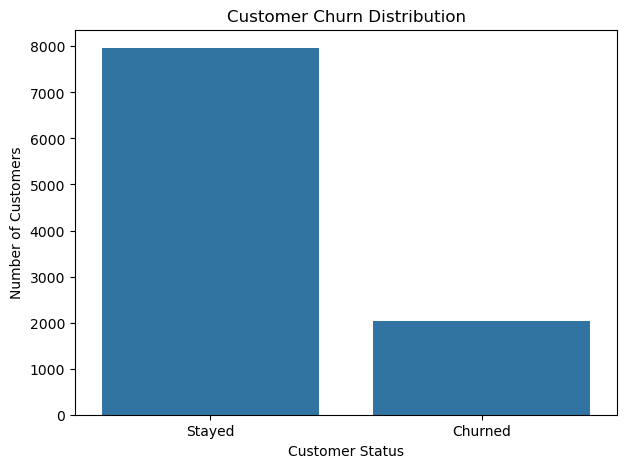

In [45]:
# cutomer churn visualization
# showing the number of customer who stayed and left the bank

churn_counts = df['Exited'].value_counts()

plt.figure(figsize=(7,5))

sns.barplot(x=['Stayed','Churned'], y=churn_counts.sort_index().values)

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.show()

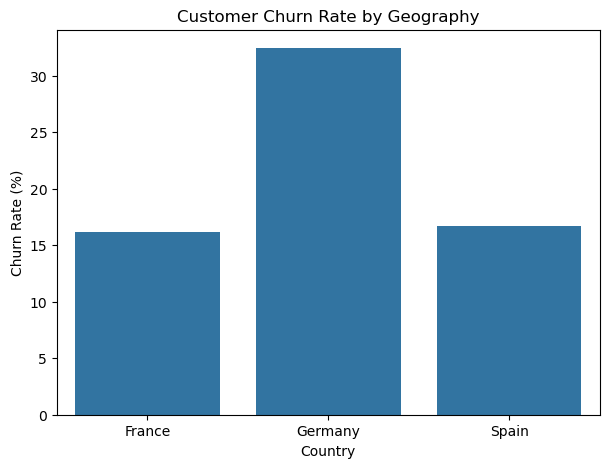

In [46]:
# churn rate by geography
# visualization customer churn pecentage across countries

geo_churn = df.groupby('Geography')['Exited'].sum()
geo_total = df.groupby('Geography')['Exited'].count()

geo_churn_rate = (geo_churn / geo_total)*100

plt.figure(figsize=(7,5))

sns.barplot(x=geo_churn_rate.index,y=geo_churn_rate.values)

plt.title('Customer Churn Rate by Geography')
plt.xlabel('Country')
plt.ylabel('Churn Rate (%)')

plt.show()

C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\3105521510.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_churn = df.groupby('Age_Group')['Exited'].sum()
C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\3105521510.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_total = df.groupby('Age_Group')['Exited'].count()


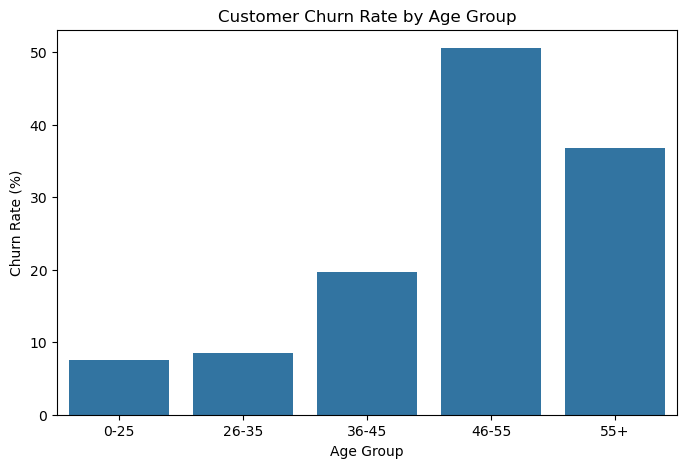

In [47]:
# customer churn rate by age group
# visualization churn pecentage across differnt age groups

age_churn = df.groupby('Age_Group')['Exited'].sum()
age_total = df.groupby('Age_Group')['Exited'].count()

age_churn_rate = (age_churn / age_total)*100

plt.figure(figsize=(8,5))

sns.barplot(x=age_churn_rate.index, y=age_churn_rate.values)

plt.title('Customer Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')

plt.show()

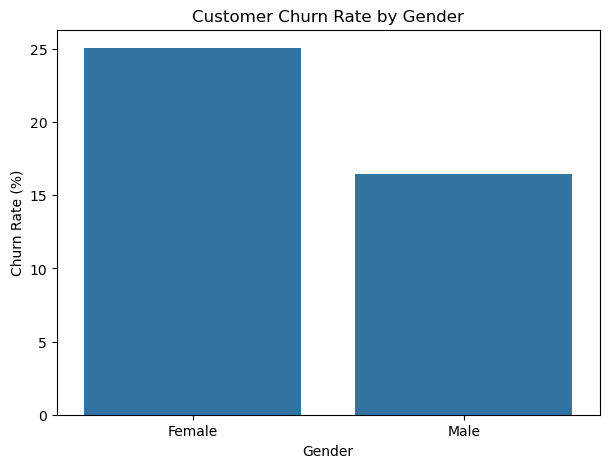

In [48]:
# customer churn rate by gender
# comparing churn percentage between male and female customers

gender_churn = df.groupby('Gender')['Exited'].sum()
gender_total = df.groupby('Gender')['Exited'].count()

gender_churn_rate = (gender_churn / gender_total)*100

plt.figure(figsize=(7,5))

sns.barplot(x=gender_churn_rate.index, y=gender_churn_rate.values)

plt.title('Customer Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')

plt.show()

C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\366573799.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  credit_churn = df.groupby('Credit_Category')['Exited'].sum()
C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\366573799.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  credit_total = df.groupby('Credit_Category')['Exited'].count()


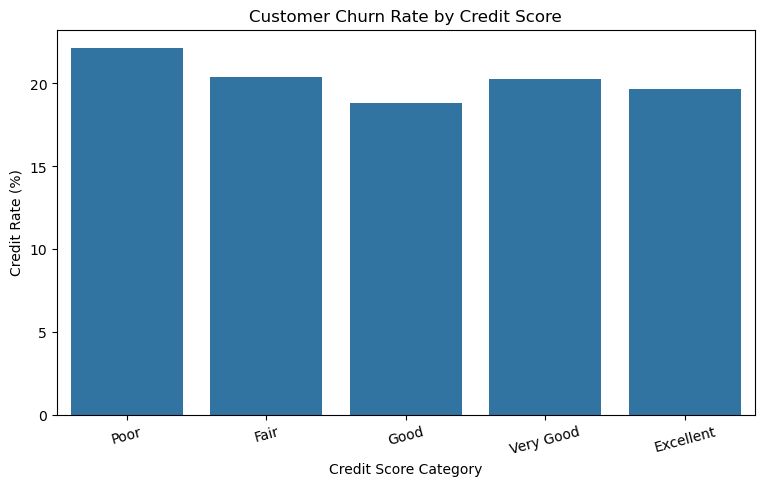

In [49]:
# customer churn rate by credit score
# comparing churnj pecentage across credit score categories

credit_churn = df.groupby('Credit_Category')['Exited'].sum()
credit_total = df.groupby('Credit_Category')['Exited'].count()

credit_churn_rate = (credit_churn / credit_total)*100

plt.figure(figsize=(9,5))

sns.barplot(x=credit_churn_rate.index, y=credit_churn_rate.values)

plt.title('Customer Churn Rate by Credit Score')
plt.xlabel('Credit Score Category')
plt.ylabel('Credit Rate (%)')
plt.xticks(rotation=15)

plt.show()

C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\1858437539.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  balance_churn = df.groupby('Balance_Category')['Exited'].sum()
C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\1858437539.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  balance_total = df.groupby('Balance_Category')['Exited'].count()


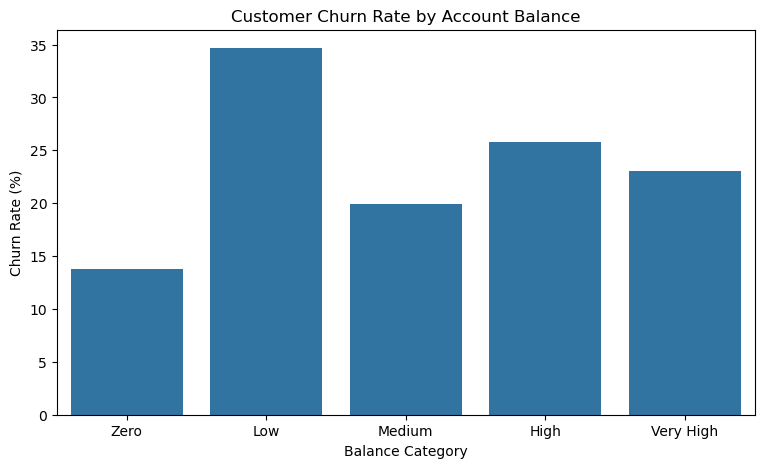

In [50]:
# customer churn rate by account balance
# comparing churn percentage across different balance categories

balance_churn = df.groupby('Balance_Category')['Exited'].sum()
balance_total = df.groupby('Balance_Category')['Exited'].count()

balance_churn_rate = (balance_churn / balance_total)*100

plt.figure(figsize=(9,5))

sns.barplot(x=balance_churn_rate.index,y=balance_churn_rate.values)

plt.title('Customer Churn Rate by Account Balance')
plt.xlabel('Balance Category')
plt.ylabel('Churn Rate (%)')

plt.show()

In [51]:
# final project summary
# display the key findings of bank customer churn analysis

print('BANK CUSTOMER ANALYSIS - FINAL SUMMARY')
print('-' * 50)

print('Total Cusotmer:', len(df))
print('Churned Customer:', df ['Exited'].sum())
print('Overall Churn Rate:', round(df['Exited'].mean() * 100,2), '%')

print('Highest Churn by Geography:', df.groupby('Geography')['Exited'].mean().idxmax())

print('Highest Churn by Gender:', df.groupby('Gender')['Exited'].mean().idxmax())

print('Average Customer Age:', round(df['Age'].mean(),2))

BANK CUSTOMER ANALYSIS - FINAL SUMMARY
--------------------------------------------------
Total Cusotmer: 10000
Churned Customer: 2037
Overall Churn Rate: 20.37 %
Highest Churn by Geography: Germany
Highest Churn by Gender: Female
Average Customer Age: 38.92


<!-- Fianl Conclusion-->
<!-- key Finding -->

1. The dataset contains 10,000 bank customers.
2. A total of 2,037 customers have left the bank.
3. The overall customer churn rate is 20.37%.
4. Germany has the highest churn rate among the three contries.
5. poor credit score customer show a relativly high churn rate.
6. Inactive members are more likely to leave the bank than active members.
7. Customer age and account balance also show differences in churn rates.

<!-- Business Recommendation-->
- Improve customer engagment and communication.
- Provide better services and offers to inactive customers.
- Identify customer who are more likely to leave.
- Focus on customer satisfaction and retention.

<!-- Project Outcome-->
This project helped analyse coustomer churn using Python, Pandas, Numpy, Matplotlib and seaborn.

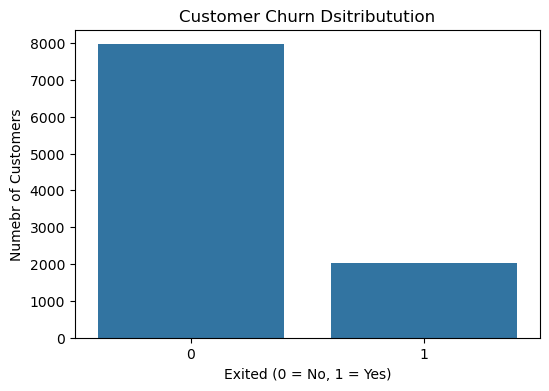

In [52]:
plt.figure(figsize=(6,4))
sns.countplot(x='Exited', data=df)
plt.title('Customer Churn Dsitributution')
plt.xlabel('Exited (0 = No, 1 = Yes)')
plt.ylabel('Numebr of Customers')
plt.savefig('../Visualizations/Churn_Distribution.png')

plt.show()

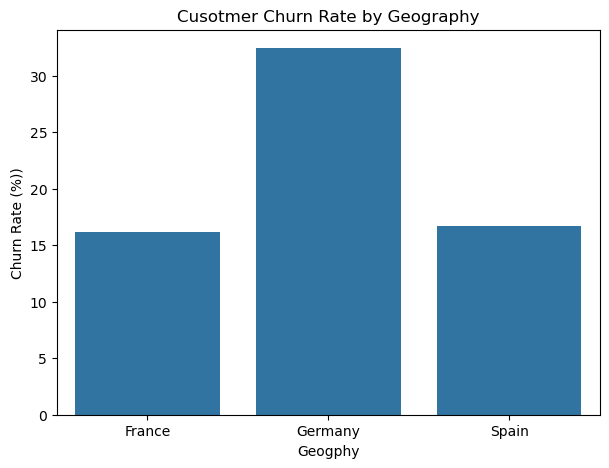

In [53]:
# save geography-wise churn rate graph

plt.figure(figsize=(7,5))

geo_churn = df.groupby('Geography')['Exited'].mean() * 100

sns.barplot(x=geo_churn.index, y=geo_churn.values)

plt.title('Cusotmer Churn Rate by Geography')
plt.xlabel('Geogphy')
plt.ylabel('Churn Rate (%))')

plt.savefig('../Visualizations/Geography_Churn_Rate.png')
plt.show()

C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\3344777439.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_churn = df.groupby('Age_Group')['Exited'].mean() * 100


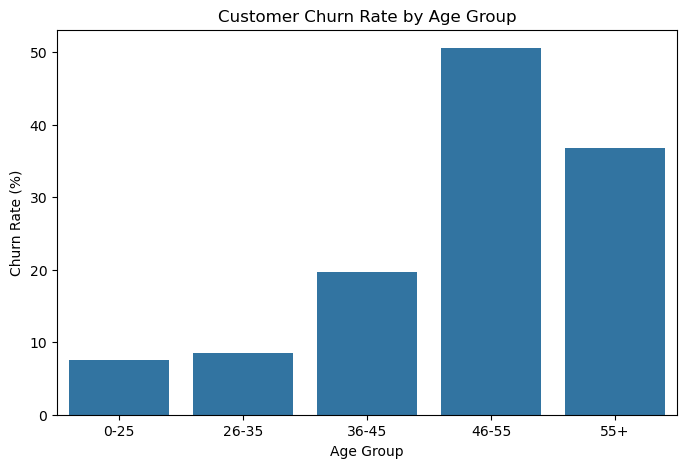

In [54]:
# save customer churn rate by age group

age_churn = df.groupby('Age_Group')['Exited'].mean() * 100

plt.figure(figsize=(8,5))

sns.barplot(x=age_churn.index, y=age_churn.values)

plt.title('Customer Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')

plt.savefig('../Visualizations/Age_Group_Churn_Rate.png')

plt.show()

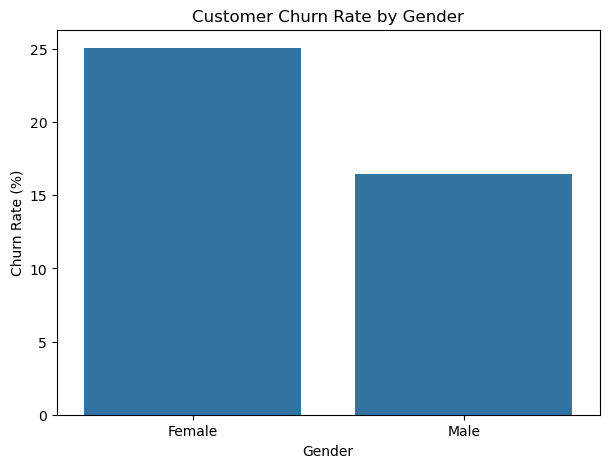

In [55]:
# save customer churn rate by gender graph

gender_churn = df.groupby('Gender')['Exited'].mean() * 100

plt.figure(figsize=(7,5))

sns.barplot(x=gender_churn.index,y=gender_churn.values)

plt.title('Customer Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')

plt.savefig('../Visualizations/Gender_Churn_Rate.png')

plt.show()

C:\Users\sharm\AppData\Local\Temp\ipykernel_6192\4133260468.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  credit_churn = df.groupby('Credit_Category')['Exited'].mean() * 100


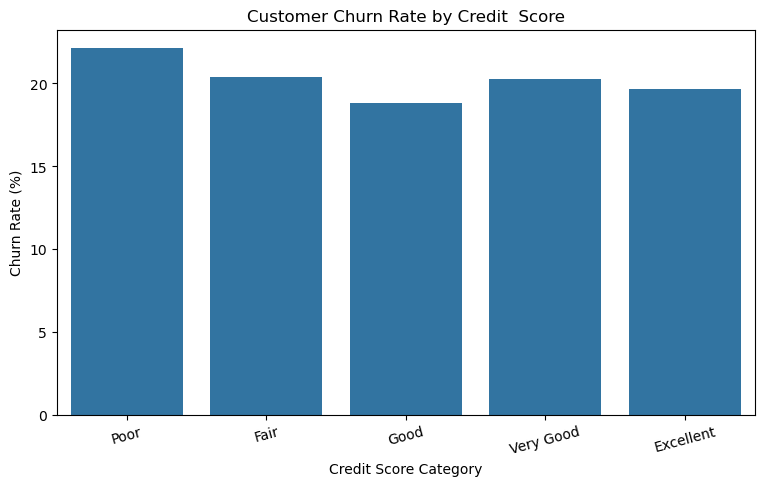

In [56]:
# save customer churn rate by credit score graph

credit_churn = df.groupby('Credit_Category')['Exited'].mean() * 100

plt.figure(figsize=(9,5))

sns.barplot(x=credit_churn.index,  y=credit_churn.values)

plt.title('Customer Churn Rate by Credit  Score')
plt.xlabel('Credit Score Category')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=15)

plt.savefig('../Visualizations/Credit_Score_Churn_Rate.png')
plt.show()